In [1]:
# Import libraries.

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Load Crop Recommendation dataset.

dataset_path = "dataset/Crop_recommendation.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully!
Shape: (2200, 8)

Columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']


In [3]:
# Basic dataset information

print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Missing values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows:
0


In [4]:
# Check crop classes and their distribution

print("Number of unique crops:", df["label"].nunique())

print("\nCrop names:")
print(sorted(df["label"].unique()))

print("\nSamples per crop:")
print(df["label"].value_counts().sort_index())

Number of unique crops: 22

Crop names:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64


In [5]:
# Statistical summary of numerical features

df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


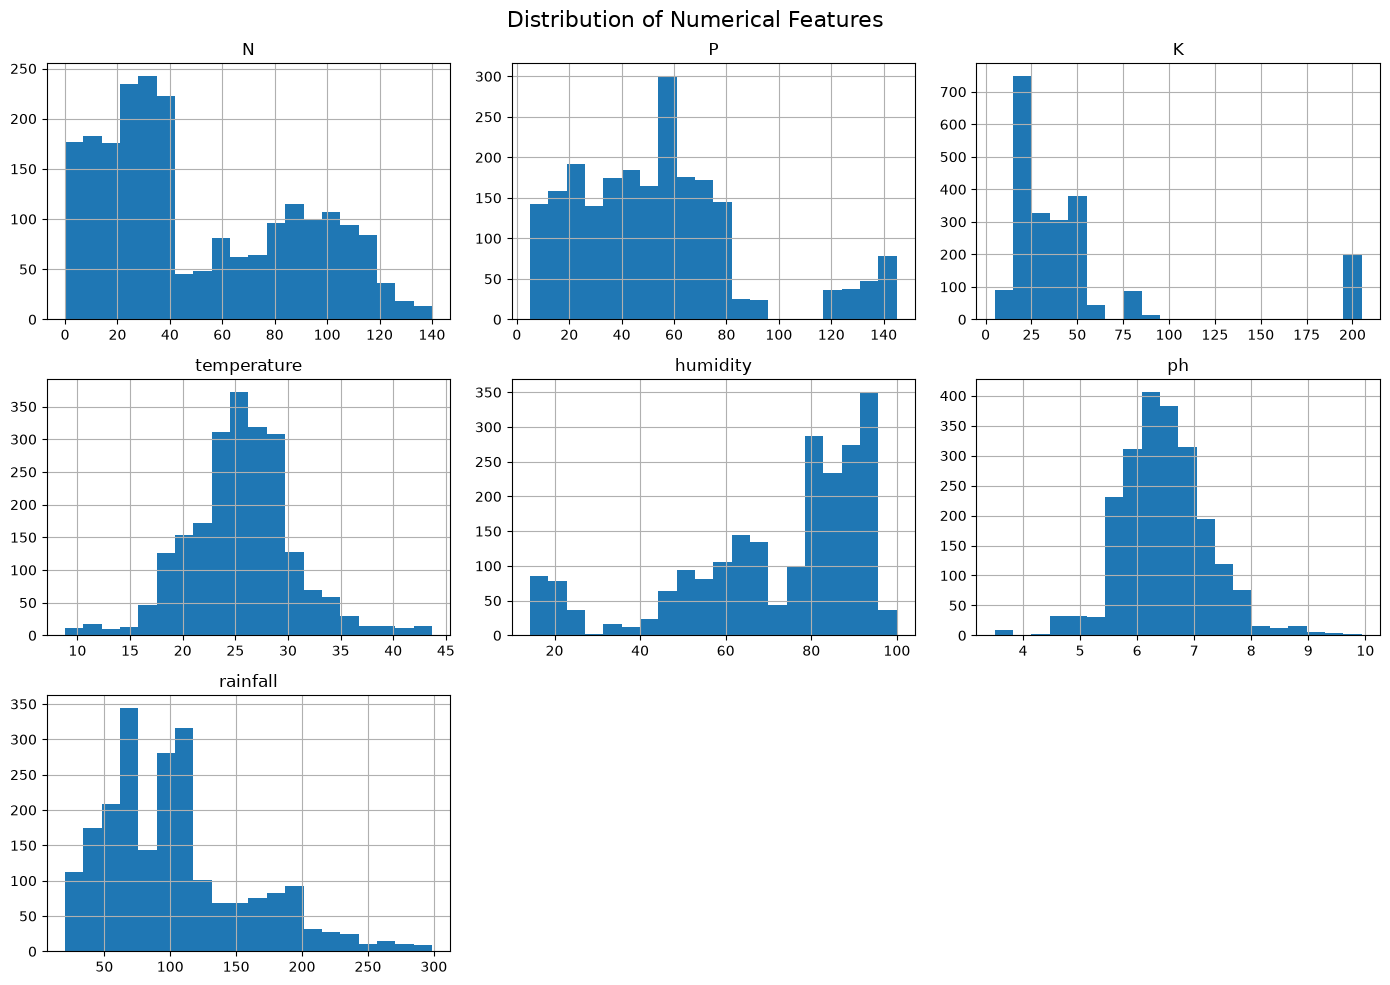

In [6]:
# Distribution of numerical features

numerical_features = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

df[numerical_features].hist(
    figsize=(14, 10),
    bins=20
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

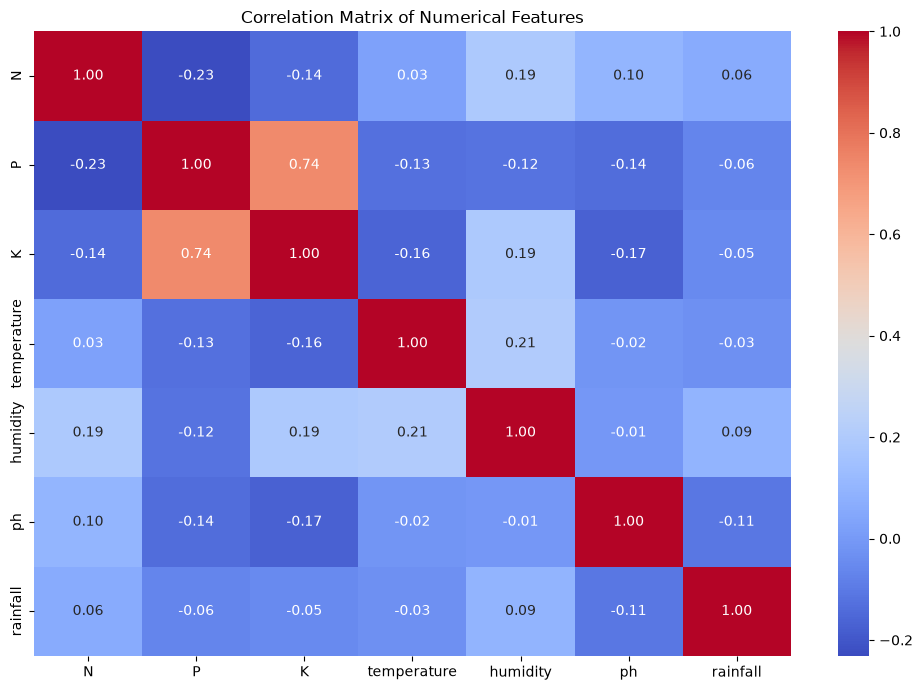

In [7]:
# Correlation matrix of numerical features

correlation = df[numerical_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
# Average numerical feature values for each crop

crop_means = df.groupby("label")[numerical_features].mean()

display(crop_means)

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.630942,92.333383,5.929663,112.654779
banana,100.23,82.01,50.05,27.376798,80.358123,5.983893,104.626980
blackgram,40.02,67.47,19.24,29.973340,65.118426,7.133952,67.884151
chickpea,40.09,67.79,79.92,18.872847,16.860439,7.336957,80.058977
coconut,21.98,16.93,30.59,27.409892,94.844272,5.976562,175.686646
coffee,101.20,28.74,29.94,25.540477,58.869846,6.790308,158.066295
cotton,117.77,46.24,19.56,23.988958,79.843474,6.912675,80.398043
grapes,23.18,132.53,200.11,23.849575,81.875228,6.025937,69.611829
jute,78.40,46.86,39.99,24.958376,79.639864,6.732778,174.792798


In [9]:
# Separate features and target

X = df[
    ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
]

y = df["label"]

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nNumber of target classes:", y.nunique())

Features (X) shape: (2200, 7)
Target (y) shape: (2200,)

Feature columns:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

Number of target classes: 22


In [10]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features :", X_test.shape)
print("Training labels  :", y_train.shape)
print("Testing labels   :", y_test.shape)

Training features: (1760, 7)
Testing features : (440, 7)
Training labels  : (1760,)
Testing labels   : (440,)


In [11]:
# Import machine learning models and preprocessing tools

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("All ML models imported successfully!")

All ML models imported successfully!


In [12]:
# Define classification models

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ])
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Logistic Regression
- Decision Tree
- Random Forest
- KNN
- SVM


In [13]:
# Train all classification models

trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!
Training Decision Tree...
Decision Tree trained successfully!
Training Random Forest...
Random Forest trained successfully!
Training KNN...
KNN trained successfully!
Training SVM...


c:\Users\risha\Documents\CODING\Minor Project\KrishiVision\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!

All models trained successfully!


In [14]:
# Evaluate all trained models on the test set

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df)

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.972727,0.974022,0.972727,0.972464
1,Decision Tree,0.979545,0.980598,0.979545,0.979423
2,Random Forest,0.995455,0.995671,0.995455,0.995452
3,KNN,0.979545,0.980356,0.979545,0.979283
4,SVM,0.984091,0.985610,0.984091,0.984038


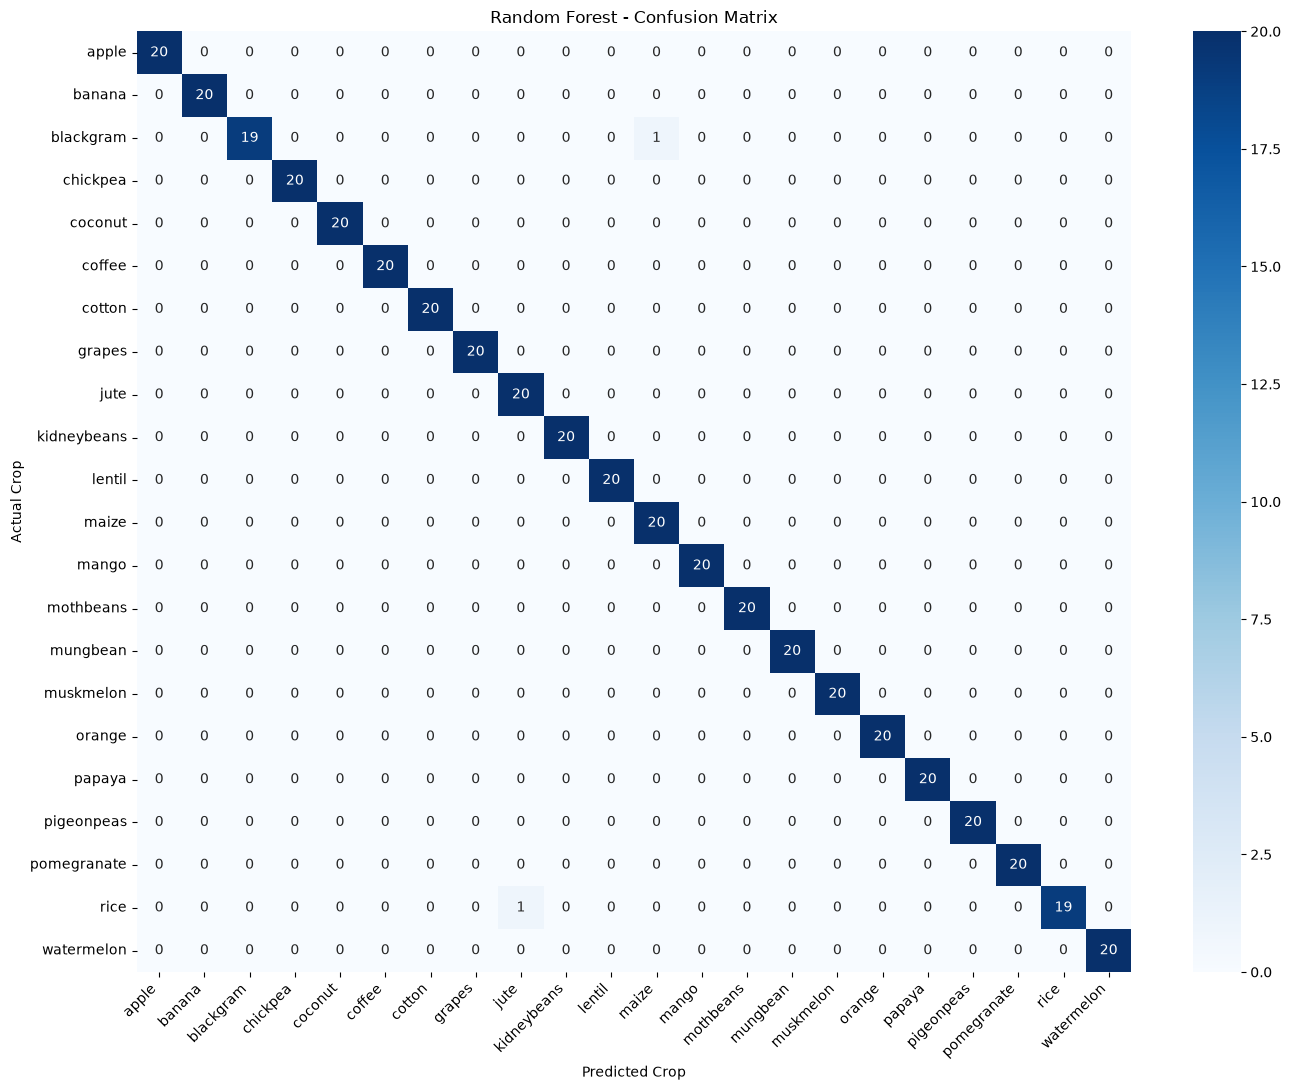

In [15]:
# Confusion matrix for Random Forest

rf_model = trained_models["Random Forest"]

y_pred_rf = rf_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
# Detailed classification report for Random Forest

print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf,
        labels=rf_model.classes_,
        target_names=rf_model.classes_,
        digits=4
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        20
      banana     1.0000    1.0000    1.0000        20
   blackgram     1.0000    0.9500    0.9744        20
    chickpea     1.0000    1.0000    1.0000        20
     coconut     1.0000    1.0000    1.0000        20
      coffee     1.0000    1.0000    1.0000        20
      cotton     1.0000    1.0000    1.0000        20
      grapes     1.0000    1.0000    1.0000        20
        jute     0.9524    1.0000    0.9756        20
 kidneybeans     1.0000    1.0000    1.0000        20
      lentil     1.0000    1.0000    1.0000        20
       maize     0.9524    1.0000    0.9756        20
       mango     1.0000    1.0000    1.0000        20
   mothbeans     1.0000    1.0000    1.0000        20
    mungbean     1.0000    1.0000    1.0000        20
   muskmelon     1.0000    1.0000    1.0000        20
      orange     1.0000    1.0000    1.0000

In [17]:
# Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Feature,Importance
6,rainfall,0.219641
4,humidity,0.217058
2,K,0.180813
1,P,0.151342
0,N,0.103356
3,temperature,0.075485
5,ph,0.052305


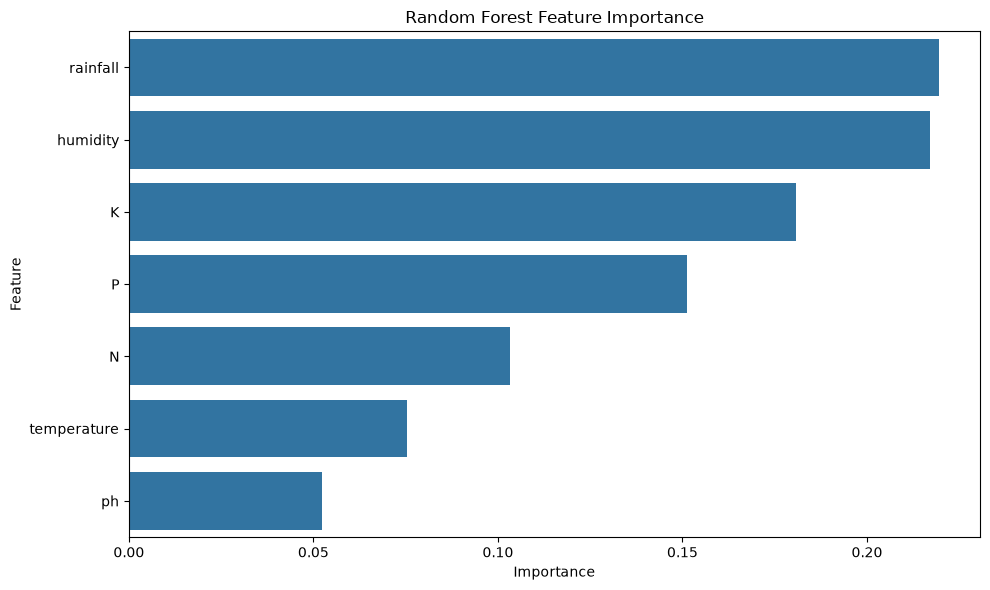

In [18]:
# Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [19]:
# Save the final Random Forest model

final_model = rf_model

model_path = "crop_model.pkl"

joblib.dump(final_model, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: crop_model.pkl


In [20]:
# Load the saved model and verify prediction

loaded_model = joblib.load("crop_model.pkl")

# Use one sample from the test set
sample = X_test.iloc[[0]]
actual_crop = y_test.iloc[0]

predicted_crop = loaded_model.predict(sample)[0]

print("Actual crop   :", actual_crop)
print("Predicted crop:", predicted_crop)

# Get prediction probability
probabilities = loaded_model.predict_proba(sample)[0]
confidence = probabilities.max() * 100

print(f"Confidence    : {confidence:.2f}%")

Actual crop   : orange
Predicted crop: orange
Confidence    : 97.50%


In [21]:
# Show the exact test sample used for verification

sample = X_test.iloc[[0]]
actual_crop = y_test.iloc[0]

print("Exact input values:")
display(sample)

print("Actual crop:", actual_crop)

print("\nPrediction from notebook:")
print("Crop:", loaded_model.predict(sample)[0])

probabilities = loaded_model.predict_proba(sample)[0]
print("Confidence:", f"{probabilities.max() * 100:.2f}%")

Exact input values:


,N,P,K,temperature,humidity,ph,rainfall
1609,13,23,6,23.961476,90.26408,7.365338,102.69587


Actual crop: orange

Prediction from notebook:
Crop: orange
Confidence: 97.50%


In [22]:
# Test the standalone inference function with real test samples

from inference import predict_crop

# Test 5 samples from the held-out test set
test_indices = [0, 1, 2, 3, 4]

for i in test_indices:
    sample = X_test.iloc[i]
    actual = y_test.iloc[i]

    result = predict_crop(
        nitrogen=sample["N"],
        phosphorus=sample["P"],
        potassium=sample["K"],
        temperature=sample["temperature"],
        humidity=sample["humidity"],
        ph=sample["ph"],
        rainfall=sample["rainfall"]
    )

    print(f"Test sample {i + 1}")
    print("Actual     :", actual)
    print("Predicted  :", result["crop"])
    print("Confidence :", f'{result["confidence"]:.2f}%')
    print("-" * 40)

Test sample 1
Actual     : orange
Predicted  : orange
Confidence : 97.50%
----------------------------------------
Test sample 2
Actual     : banana
Predicted  : banana
Confidence : 93.50%
----------------------------------------
Test sample 3
Actual     : cotton
Predicted  : cotton
Confidence : 98.50%
----------------------------------------
Test sample 4
Actual     : maize
Predicted  : maize
Confidence : 99.50%
----------------------------------------
Test sample 5
Actual     : orange
Predicted  : orange
Confidence : 97.50%
----------------------------------------


In [23]:
for i in [1, 2, 3]:
    sample = X_test.iloc[i]

    print(f"\nTest sample {i + 1}")
    print(f'{{"nitrogen":{sample["N"]},"phosphorus":{sample["P"]},"potassium":{sample["K"]},"temperature":{sample["temperature"]},"humidity":{sample["humidity"]},"ph":{sample["ph"]},"rainfall":{sample["rainfall"]}}}')


Test sample 2
{"nitrogen":98.0,"phosphorus":79.0,"potassium":50.0,"temperature":25.34119774,"humidity":84.47321314,"ph":6.435917308,"rainfall":91.06493353}

Test sample 3
{"nitrogen":140.0,"phosphorus":38.0,"potassium":15.0,"temperature":24.1472953,"humidity":75.88298598,"ph":6.021439523,"rainfall":69.91563467}

Test sample 4
{"nitrogen":71.0,"phosphorus":54.0,"potassium":16.0,"temperature":22.61359953,"humidity":63.69070564,"ph":5.7499144210000015,"rainfall":87.75953857}
